## Importing libs

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

## Data Processing and Preprocessing

In [ ]:
data = pd.read_csv('phishing_website_dataset.csv')
df = pd.DataFrame(data)

In [ ]:
if 'index' in df.columns:
    df = df.drop(columns=['index'])

print("Duplicate rows in dataset:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates dropped")

Duplicate rows in dataset: 5206
Duplicates dropped


In [ ]:
print(df.corr(numeric_only=True)['Result'].sort_values(ascending=False))

Result                         1.000000
SSLfinal_State                 0.693228
URL_of_Anchor                  0.679125
Prefix_Suffix                  0.381134
having_Sub_Domain              0.296214
web_traffic                    0.281709
SFH                            0.281131
Links_in_tags                  0.243864
Request_URL                    0.237778
Google_Index                   0.118217
Statistical_report             0.108486
having_IPhaving_IP_Address     0.104952
Links_pointing_to_page         0.068463
age_of_domain                  0.062800
URLURL_Length                  0.058228
Page_Rank                      0.048140
having_At_Symbol               0.034757
DNSRecord                      0.033204
port                           0.014201
on_mouseover                   0.012790
RightClick                     0.009286
Submitting_to_email           -0.008014
Iframe                        -0.011756
popUpWidnow                   -0.022455
Favicon                       -0.025457


In [ ]:
X = df.drop(columns=['Result'])
y = df['Result'].map({-1: 1, 1: 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2]
}

grid_search = GridSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42),
    param_grid,
    cv=5,
    scoring='f1'
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best F1 score:", grid_search.best_score_)

Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Best F1 score: 0.9536244735359357


In [ ]:
log_reg = LogisticRegression()
dt_clf = DecisionTreeClassifier(random_state=42)
rf_clf = RandomForestClassifier(random_state=42)
xgb_clf = grid_search.best_estimator_

In [ ]:
log_reg.fit(X_train_scaled, y_train)
dt_clf.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
y_pred_log = log_reg.predict(X_test_scaled)
y_pred_dt = dt_clf.predict(X_test)
y_pred_rf = rf_clf.predict(X_test)
y_pred_xgb = xgb_clf.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [ ]:
acc_score_log = accuracy_score(y_test, y_pred_log)
acc_score_dt = accuracy_score(y_test, y_pred_dt)
acc_score_rf = accuracy_score(y_test, y_pred_rf)
acc_score_xgb = accuracy_score(y_test, y_pred_xgb)

print("Logistic Regression Accuracy:", acc_score_log)
print("Decision Tree Accuracy:", acc_score_dt)
print("Random Forest Accuracy:", acc_score_rf)
print("XGBoost Accuracy:", acc_score_xgb)

Logistic Regression Accuracy: 0.9179487179487179
Decision Tree Accuracy: 0.9111111111111111
Random Forest Accuracy: 0.9393162393162393
XGBoost Accuracy: 0.9495726495726495


In [ ]:
from sklearn.model_selection import cross_val_score

for name, model in [("Logistic Regression", log_reg), ("Decision Tree", dt_clf), ("Random Forest", rf_clf), ("XGBoost", xgb_clf)]:
    # Use scaled X for Logistic Regression, raw X for trees
    X_data = X_train_scaled if name == "Logistic Regression" else X_train
    y_data = y_train if name == "Logistic Regression" else y_train

    scores = cross_val_score(model, X_data, y_data, cv=5, scoring='accuracy')
    print(f"{name} CV Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression CV Accuracy: 0.9201 (+/- 0.0032)
Decision Tree CV Accuracy: 0.9203 (+/- 0.0115)
Random Forest CV Accuracy: 0.9461 (+/- 0.0038)
XGBoost CV Accuracy: 0.9523 (+/- 0.0035)


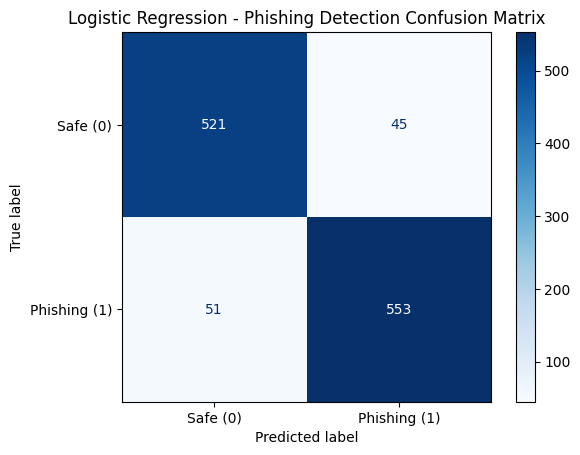

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    log_reg, X_test_scaled, y_test,
    cmap='Blues', display_labels=['Safe (0)', 'Phishing (1)']
)
plt.title('Logistic Regression - Phishing Detection Confusion Matrix')
plt.grid(False)
plt.show()

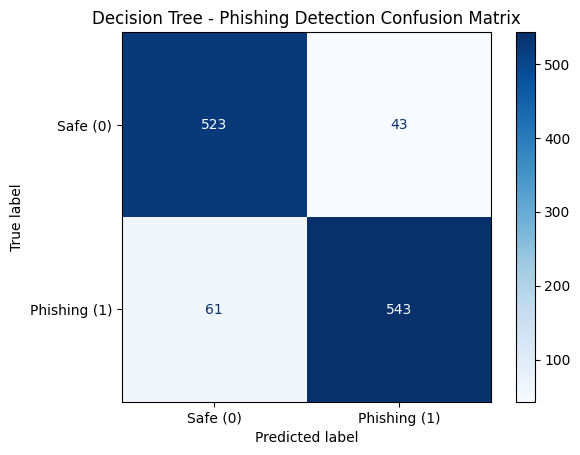

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    dt_clf, X_test, y_test,
    cmap='Blues', display_labels=['Safe (0)', 'Phishing (1)']
)
plt.title('Decision Tree - Phishing Detection Confusion Matrix')
plt.grid(False)
plt.show()

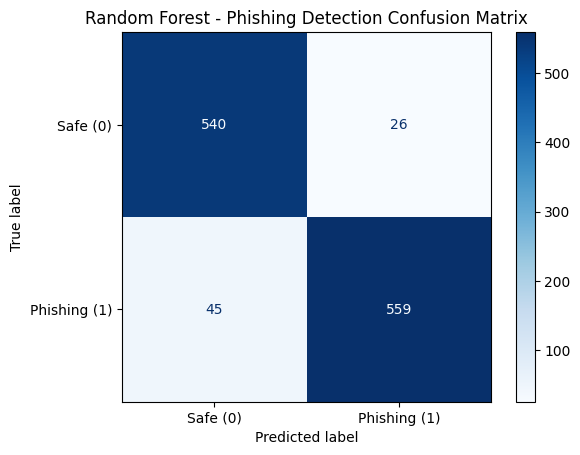

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    rf_clf, X_test, y_test,
    cmap='Blues', display_labels=['Safe (0)', 'Phishing (1)']
)
plt.title('Random Forest - Phishing Detection Confusion Matrix')
plt.grid(False)
plt.show()

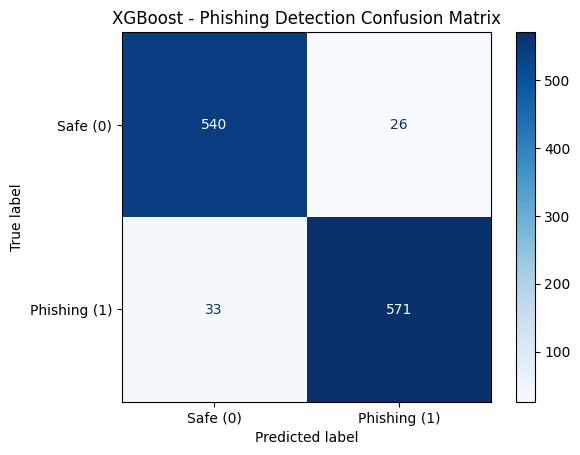

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    xgb_clf, X_test, y_test,
    cmap='Blues', display_labels=['Safe (0)', 'Phishing (1)']
)
plt.title('XGBoost - Phishing Detection Confusion Matrix')
plt.grid(False)
plt.show()

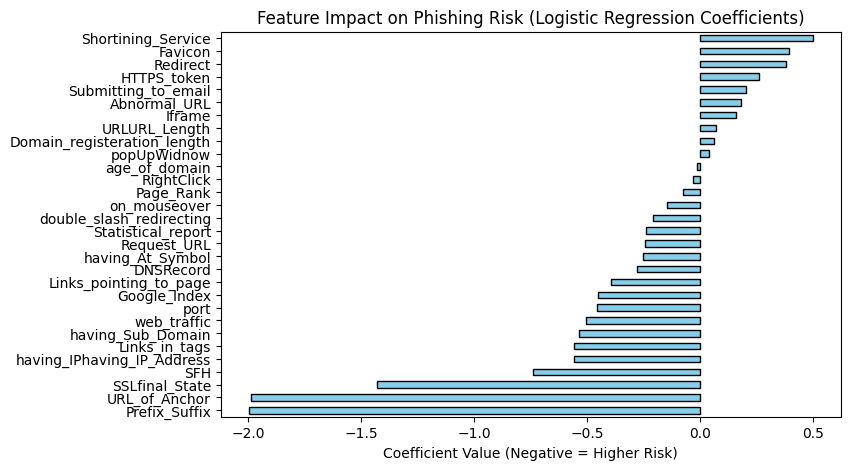

In [ ]:
log_coef = pd.Series(log_reg.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
log_coef.plot(kind='barh', color='skyblue', edgecolor='black')
plt.title("Feature Impact on Phishing Risk (Logistic Regression Coefficients)")
plt.xlabel("Coefficient Value (Negative = Higher Risk)")
plt.show()

<Figure size 600x500 with 0 Axes>

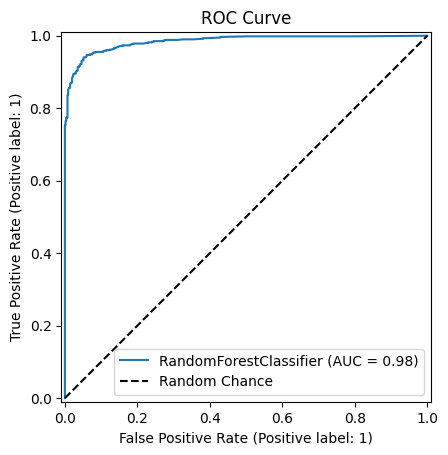

In [ ]:
plt.figure(figsize=(6, 5))
RocCurveDisplay.from_estimator(rf_clf, X_test, y_test)
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.title("ROC Curve")
plt.legend()
plt.show()

<Figure size 600x500 with 0 Axes>

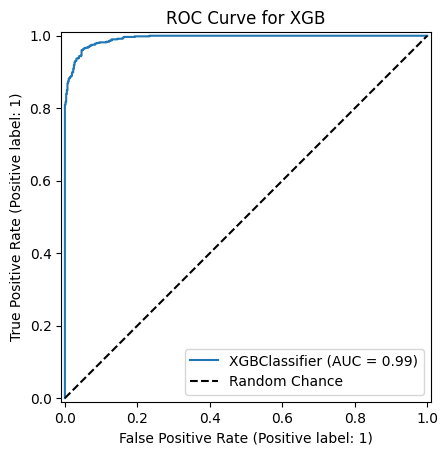

In [ ]:
plt.figure(figsize=(6, 5))
RocCurveDisplay.from_estimator(xgb_clf, X_test, y_test)
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.title("ROC Curve for XGB")
plt.legend()
plt.show()

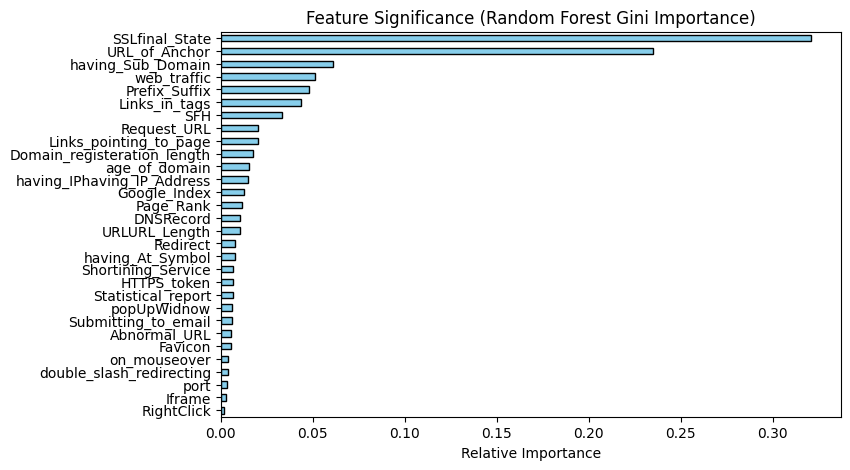

In [ ]:
import shap

importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='skyblue', edgecolor='black')
plt.title("Feature Significance (Random Forest Gini Importance)")
plt.xlabel("Relative Importance")
plt.show()

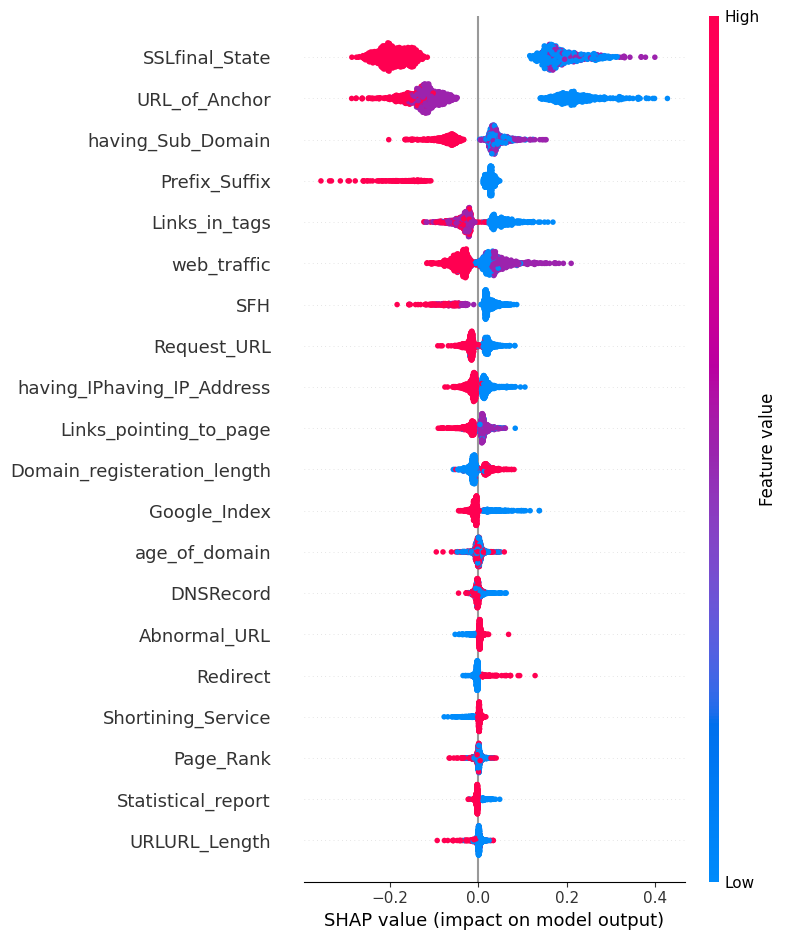

In [ ]:
# SHAP Summary Plot (Shows feature significance + direction of impact)
explainer = shap.TreeExplainer(rf_clf)
shap_values = explainer(X_test)

if len(shap_values.shape) == 3:
    shap_vals_to_plot = shap_values[:, :, 1]
else:
    shap_vals_to_plot = shap_values

plt.figure()
shap.summary_plot(shap_vals_to_plot, X_test)

## Classification Reports for Algos

In [ ]:
from sklearn.metrics import classification_report
print("Classification Report for Logistic Regression")
print(classification_report(y_test, y_pred_log, target_names=['Safe (0)', 'Phishing (1)']))
print("Classification Report for Decision Tree")
print(classification_report(y_test, y_pred_dt, target_names=['Safe (0)', 'Phishing (1)']))
print("Classification Report for Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=['Safe (0)', 'Phishing (1)']))
print("Classification Report for XGBoost")
print(classification_report(y_test, y_pred_xgb, target_names=['Safe (0)', 'Phishing (1)']))

Classification Report for Logistic Regression
              precision    recall  f1-score   support

    Safe (0)       0.91      0.92      0.92       566
Phishing (1)       0.92      0.92      0.92       604

    accuracy                           0.92      1170
   macro avg       0.92      0.92      0.92      1170
weighted avg       0.92      0.92      0.92      1170

Classification Report for Decision Tree
              precision    recall  f1-score   support

    Safe (0)       0.90      0.92      0.91       566
Phishing (1)       0.93      0.90      0.91       604

    accuracy                           0.91      1170
   macro avg       0.91      0.91      0.91      1170
weighted avg       0.91      0.91      0.91      1170

Classification Report for Random Forest
              precision    recall  f1-score   support

    Safe (0)       0.92      0.95      0.94       566
Phishing (1)       0.96      0.93      0.94       604

    accuracy                           0.94      1170
  